# Project :- Google Trends Search Analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pytrends.request import TrendReq
import warnings
warnings.filterwarnings('ignore')

### Setup PyTrends library and keyword define


In [2]:
pytrend = TrendReq(hl='en-US',tz=360)
keywords = 'cloud computing'

### Data Request

In [3]:
pytrend.build_payload([keywords], cat = 0,timeframe = 'today 12-m', geo = '',gprop = '')


### Country wise interest

In [4]:
region_data = pytrend.interest_by_region()
region_data = region_data.sort_values(by = keywords,ascending = False).head(15)


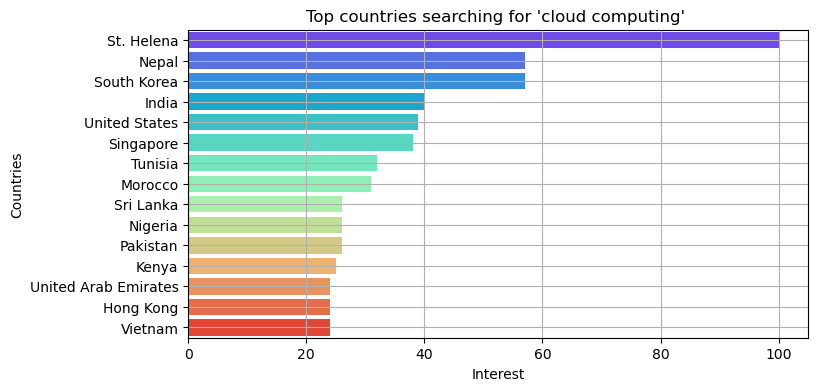

In [5]:
plt.figure(figsize = (8,4))
sns.barplot(x=region_data['cloud computing'] , y=region_data.index,palette = 'rainbow')
plt.title(f"Top countries searching for '{keywords}' ")
plt.xlabel("Interest")
plt.ylabel("Countries")
plt.grid(True)
plt.show()

### World Map 

In [6]:
region_data = region_data.reset_index()
region_data.head()

,geoName,cloud computing
0,St. Helena,100
1,Nepal,57
2,South Korea,57
3,India,40
4,United States,39


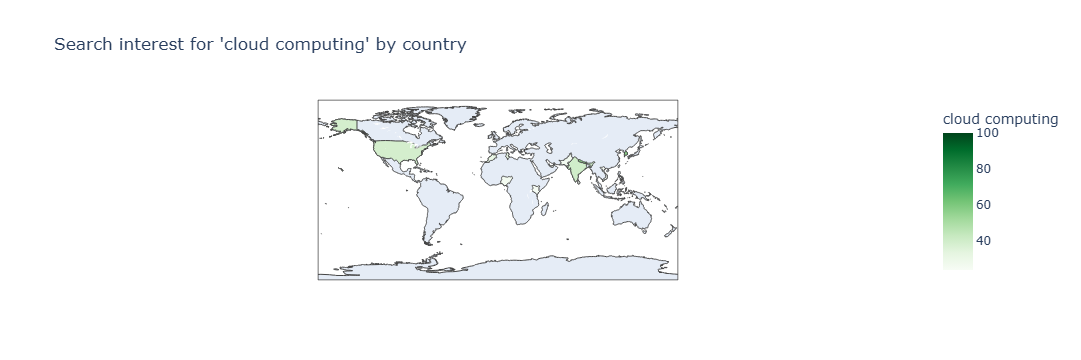

<Figure size 800x800 with 0 Axes>

In [7]:
plt.figure(figsize=(8,8))
fig = px.choropleth(region_data,
                    locations = "geoName",
                    locationmode = "country names",
                    color = keywords,
                    title = f"Search interest for '{keywords}' by country",
                    color_continuous_scale = 'Greens')

fig.show()

### Time wise interest

In [8]:
time_dist = pytrend.interest_over_time()
time_dist.head()

,cloud computing,isPartial
date,,
2025-07-27,21,False
2025-08-03,24,False
2025-08-10,29,False
2025-08-17,32,False
2025-08-24,28,False


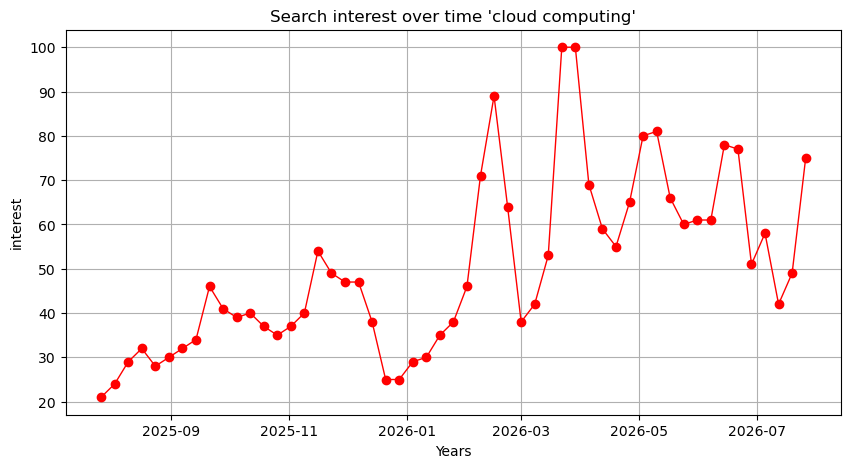

In [9]:
plt.figure(figsize = (10,5))
plt.plot(time_dist.index,time_dist[keywords],
         color = 'red',marker = 'o',lw =1)
plt.title(f"Search interest over time '{keywords}'")
plt.xlabel("Years")
plt.ylabel("interest")
plt.grid(True)
plt.show()

### Multile Keywords Compare

In [12]:
keyword_list = ['data science','cloud computing','machine learning']
pytrend.build_payload(keyword_list,cat = 0,timeframe = 'today 12-m', geo = '',gprop = '')

In [16]:
time_dist = pytrend.interest_over_time()
time_dist.head()

,data science,cloud computing,machine learning,isPartial
date,,,,
2025-07-27,23,6,28,False
2025-08-03,30,7,36,False
2025-08-10,38,8,51,False
2025-08-17,39,9,49,False
2025-08-24,34,8,39,False


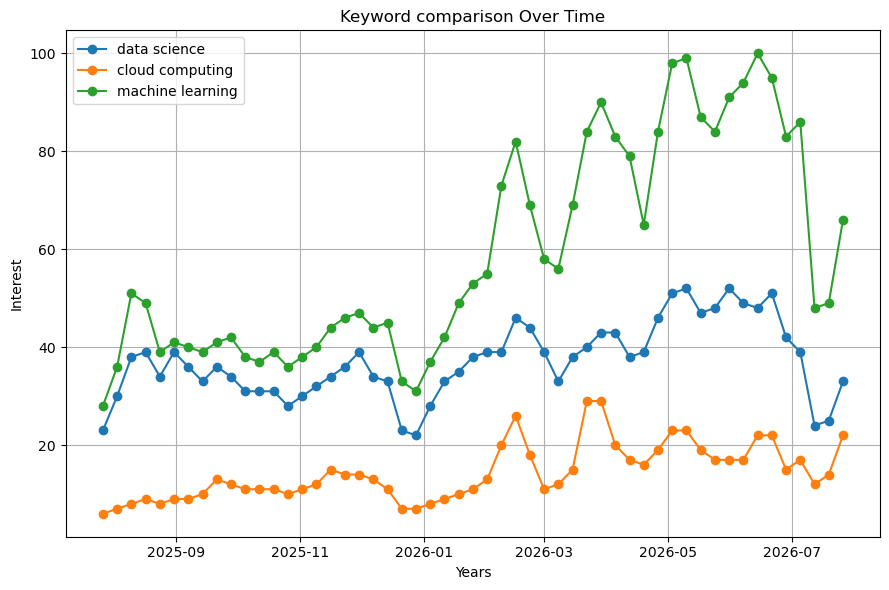

In [18]:
plt.figure(figsize = (9,6))
for kds in keyword_list:
    plt.plot(time_dist.index,time_dist[kds],marker= 'o',label = kds)
plt.title("Keyword comparison Over Time")
plt.xlabel("Years")
plt.ylabel("Interest")
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()